# Comparison: MNIST Digits and Fashion-MNIST

This notebook reads the two cached pipeline runs. It does not train. Open it from the repo root after both `scripts/mnist_vae_comparison/cache_reference.py` copies exist.

Each cache is one VAE. Optuna chose the latent size by minimizing validation ELBO loss on that dataset's train split. Reconstruction grids decode the posterior mean. The sample grids decode draws from the unit normal prior. MSE is per pixel on pixels in `[-1, 1]`. ELBO is the negative of the per-image sum of squares plus KL. A higher ELBO is a better likelihood bound.

The score bars read `evaluation_test.json`. The domain-KID bars and the latent scatters encode `reference/<dataset>/models/mnist_vae.pt` and draw new prior samples from that checkpoint. Weights stay as cached.


In [1]:
import json
from pathlib import Path

from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
for _candidate in (ROOT, *ROOT.parents):
    if (_candidate / "pyproject.toml").is_file():
        ROOT = _candidate
        break

RUNS = ("mnist_digits", "fashion_mnist")

def cache(name: str) -> Path:
    path = ROOT / "reference" / name
    needed = [
        path / "reports" / "evaluation_test.json",
        path / "reports" / "evaluation_train.json",
        path / "reports" / "best_params.json",
        path / "reports" / "plots" / "reconstructions_test.png",
        path / "reports" / "plots" / "generated_samples.png",
        path / "reports" / "plots" / "loss.png",
        path / "reports" / "plots" / "loss_vs_latent.png",
        path / "data" / "pixels.npy",
        path / "data" / "images.parquet",
        path / "data" / "split.json",
        path / "models" / "mnist_vae.pt",
    ]
    missing = [str(item.relative_to(ROOT)) for item in needed if not item.is_file()]
    if missing:
        raise FileNotFoundError(
            "missing cached files: " + ", ".join(missing) + ". Run the dataset, then cache_reference.py."
        )
    return path

paths = {name: cache(name) for name in RUNS}
print("caches", ", ".join(str(path.relative_to(ROOT)) for path in paths.values()))


caches reference\mnist_digits, reference\fashion_mnist


## Held-out scores

Stage 06 scores the official test split. The test split was not used to choose the latent size.


In [2]:
rows = []
for name in RUNS:
    report = paths[name] / "reports"
    test = json.loads((report / "evaluation_test.json").read_text(encoding="utf-8"))
    train = json.loads((report / "evaluation_train.json").read_text(encoding="utf-8"))
    params = json.loads((report / "best_params.json").read_text(encoding="utf-8"))
    rows.append(
        {
            "dataset": name,
            "latent_dim": int(test["latent_dim"]),
            "test_mse": test["mse"],
            "test_mae": test["mae"],
            "test_kl": test["kl"],
            "test_elbo": test["elbo"],
            "train_elbo": train["elbo"],
            "val_loss": params["val_loss"],
            "n_test": test["n_test"],
        }
    )

header = (
    "dataset", "latent", "test mse", "test mae", "test kl", "test elbo", "train elbo", "val loss",
)
print(" | ".join(header))
print(" | ".join("---" for _ in header))
for row in rows:
    print(
        f"{row['dataset']} | {row['latent_dim']} | {row['test_mse']:.4f} | {row['test_mae']:.4f} | "
        f"{row['test_kl']:.2f} | {row['test_elbo']:.2f} | {row['train_elbo']:.2f} | {row['val_loss']:.2f}"
    )


dataset | latent | test mse | test mae | test kl | test elbo | train elbo | val loss
--- | --- | --- | --- | --- | --- | --- | ---
mnist_digits | 8 | 0.0852 | 0.1227 | 15.41 | -82.21 | -78.97 | 117.77
fashion_mnist | 8 | 0.0749 | 0.1539 | 12.34 | -71.09 | -69.21 | 95.93


## Reconstructions, prior samples, and the latent-size curve

Top row of each reconstruction figure is the original. The bottom row is the posterior mean. The sample figure is 64 draws from `N(0, I)`. The curve is validation ELBO loss against latent size, averaged over trials that share a size. Lower validation loss is the quantity Optuna minimized.


## mnist_digits

Test reconstructions

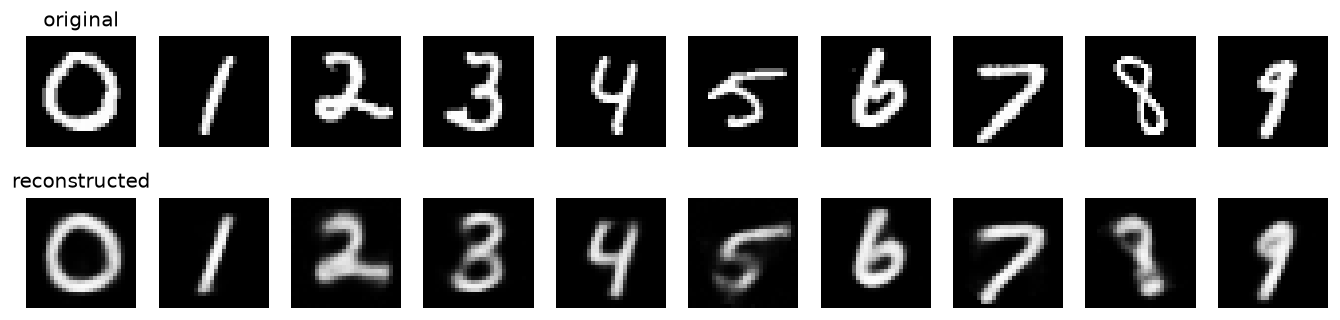

Samples from the prior

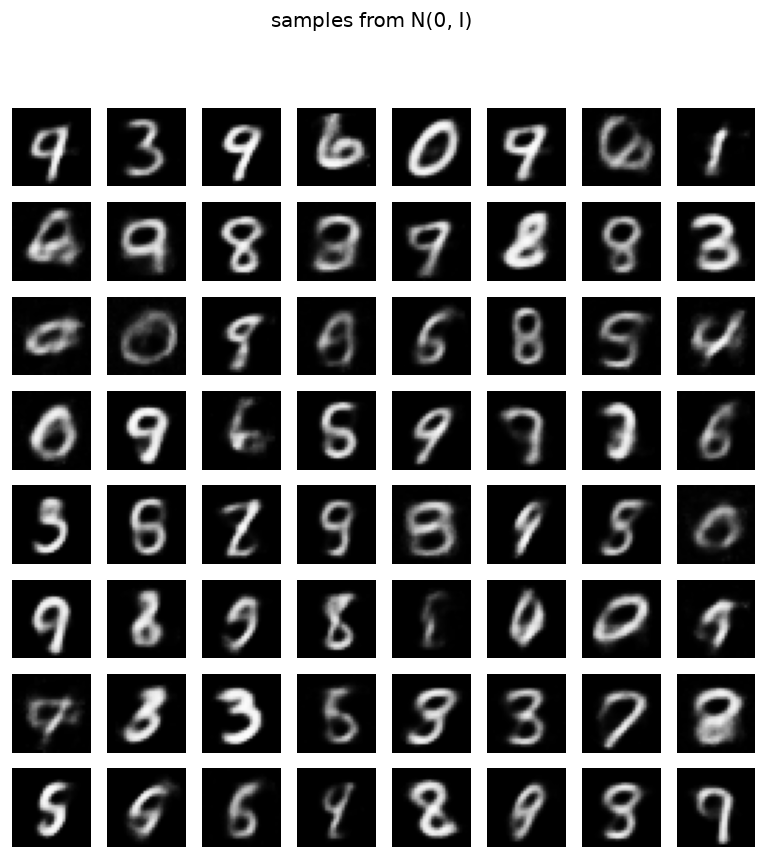

Validation loss against latent size

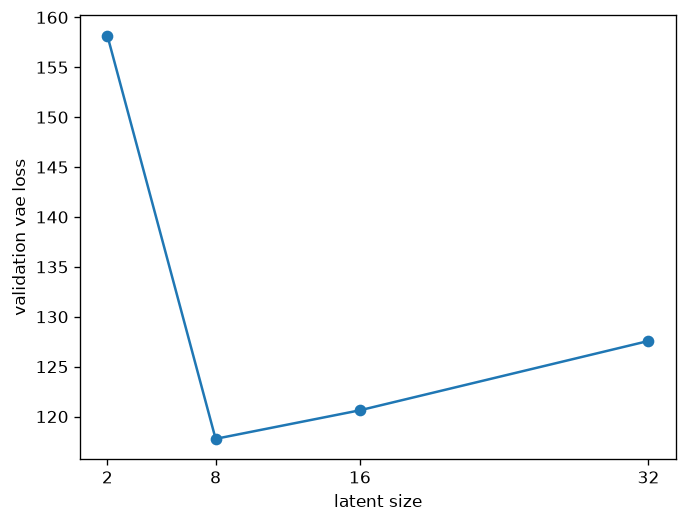

Train and test ELBO loss

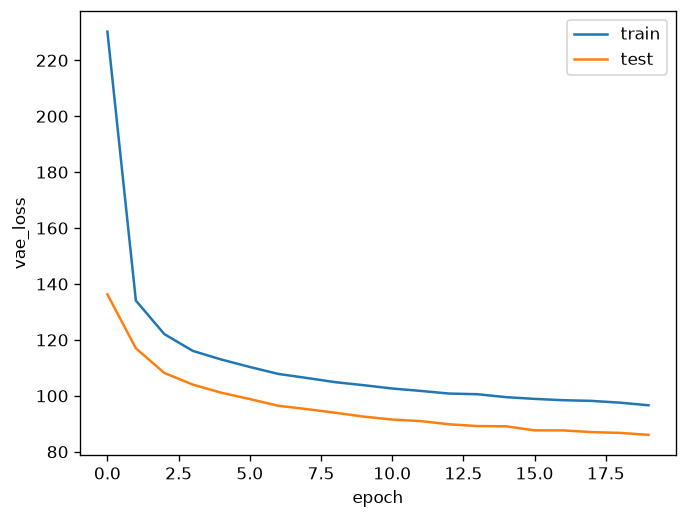

## fashion_mnist

Test reconstructions

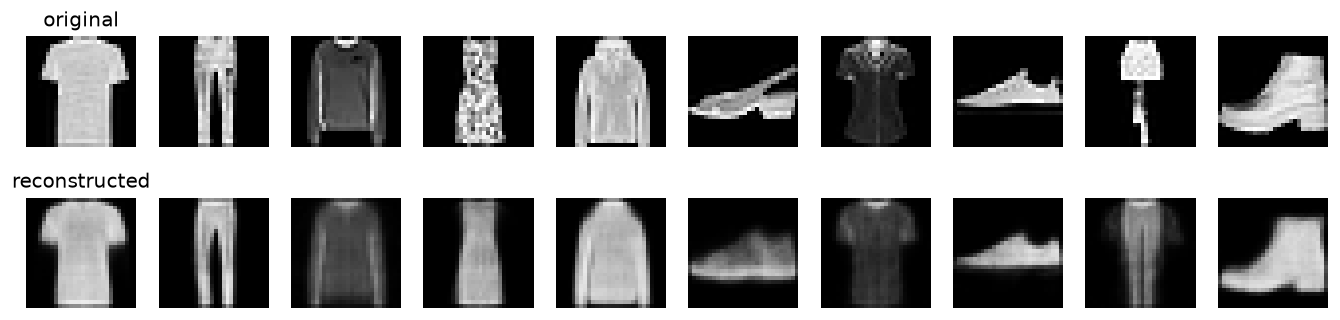

Samples from the prior

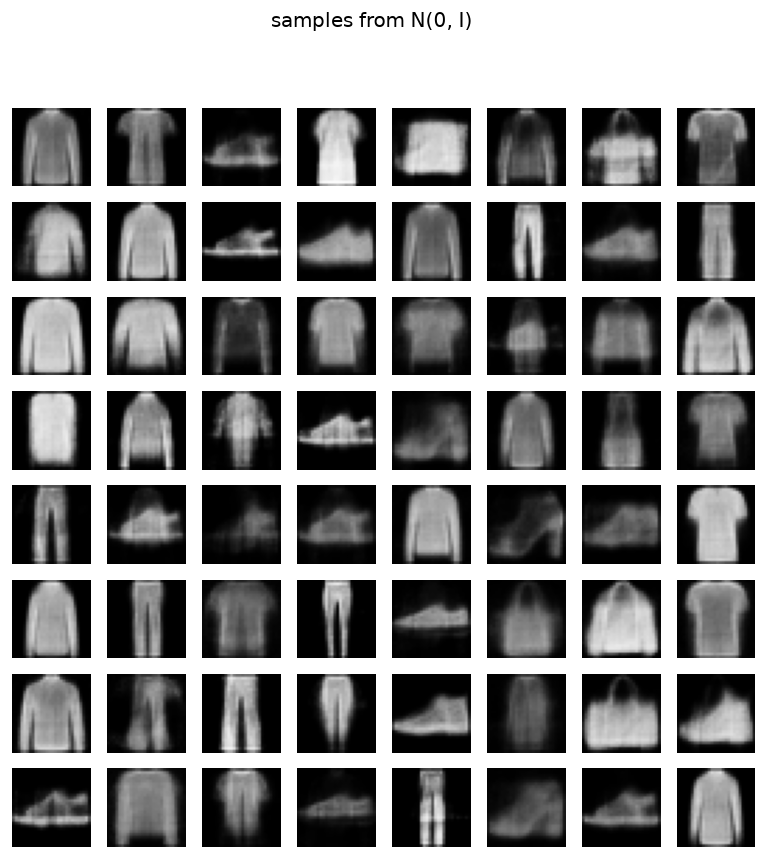

Validation loss against latent size

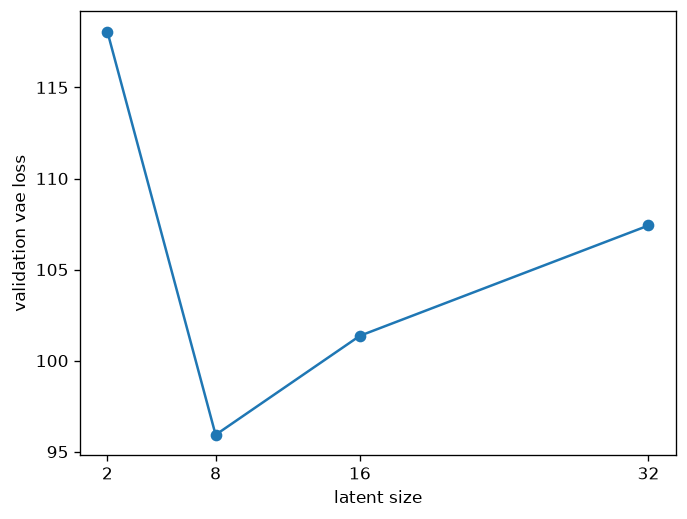

Train and test ELBO loss

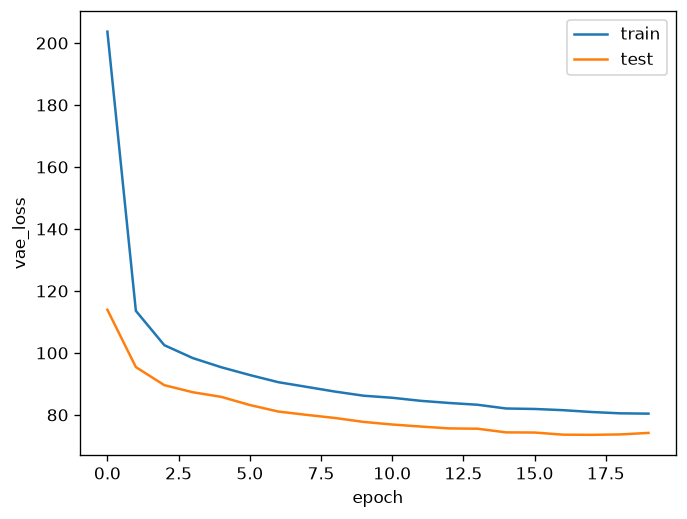

In [3]:
for name in RUNS:
    plots = paths[name] / "reports" / "plots"
    display(Markdown(f"## {name}"))
    display(Markdown("Test reconstructions"))
    display(Image(filename=str(plots / "reconstructions_test.png")))
    display(Markdown("Samples from the prior"))
    display(Image(filename=str(plots / "generated_samples.png")))
    display(Markdown("Validation loss against latent size"))
    display(Image(filename=str(plots / "loss_vs_latent.png")))
    display(Markdown("Train and test ELBO loss"))
    display(Image(filename=str(plots / "loss.png")))


## Test ELBO and reconstruction MSE

Test ELBO is how well the VAE models its own test images. It is the negative of the per-image sum of squares plus KL, decoding the posterior mean. A higher bar is a tighter likelihood bound.

Reconstruction MSE is how well that decode matches the image. It is the per-pixel mean squared error on pixels in `[-1, 1]`. A lower bar is a closer reconstruction.

Both bars read the cached `evaluation_test.json`. Each model is scored on its own test split.


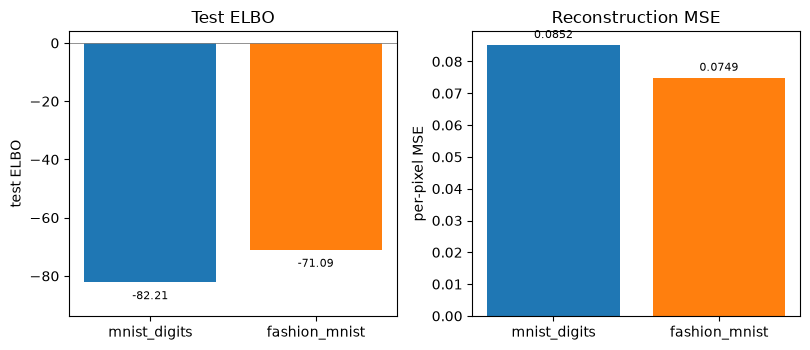

In [4]:
import matplotlib.pyplot as plt

names = [row["dataset"] for row in rows]
colors = ["C0", "C1"]
elbo_values = [row["test_elbo"] for row in rows]
mse_values = [row["test_mse"] for row in rows]

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.6))
elbo_ax, mse_ax = axes
elbo_bars = elbo_ax.bar(names, elbo_values, color=colors)
elbo_ax.axhline(0, color="0.5", linewidth=0.6)
elbo_ax.set_ylim(min(elbo_values) * 1.14, 4)
elbo_ax.set_ylabel("test ELBO")
elbo_ax.set_title("Test ELBO")
mse_bars = mse_ax.bar(names, mse_values, color=colors)
mse_ax.set_ylabel("per-pixel MSE")
mse_ax.set_title("Reconstruction MSE")


def label_bars(axis, bars, fmt):
    for bar in bars:
        value = bar.get_height()
        axis.annotate(
            format(value, fmt),
            xy=(bar.get_x() + bar.get_width() / 2, value),
            ha="center",
            va="top" if value < 0 else "bottom",
            fontsize=8,
            xytext=(0, -6 if value < 0 else 3),
            textcoords="offset points",
            clip_on=False,
        )


label_bars(elbo_ax, elbo_bars, ".2f")
label_bars(mse_ax, mse_bars, ".4f")
fig.tight_layout()
plt.show()


## Domain KID and the latent space

Domain KID is how well the model generates realistic images. It is the unbiased polynomial-kernel MMD of degree 3 between the test images and the same number of draws from `N(0, I)`. The feature map is a spatial summary of the 28×28 image: non-overlapping block means at widths 2, 4, and 7, plus the image mean and standard deviation. Both sets are centered and scaled with the real-image statistics. A lower score means the prior samples sit closer to that dataset's test images.

The scatters are the test-set posterior means. PCA and t-SNE show how those codes separate by class. Digits and garments use different label names, so each row has its own legend.

The cells load `reference/<dataset>/models/mnist_vae.pt` and the cached pixels. Prior draws use `RANDOM_SEED`.


dataset | domain kid
--- | ---
mnist_digits | 3.1052
fashion_mnist | 0.2043


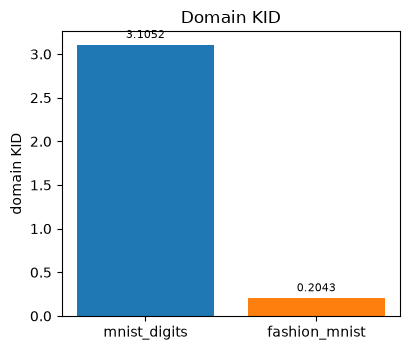

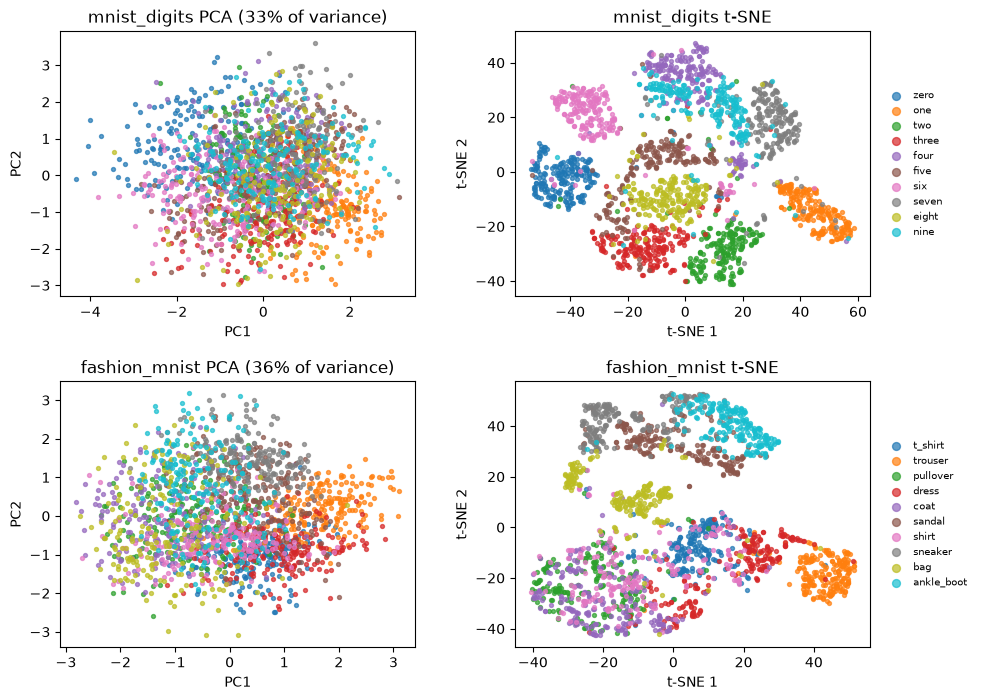

In [5]:
import numpy as np
import torch
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from mnist_vae_comparison.config import LABEL_NAMES, MODELING_CONTRACT_PATH, RANDOM_SEED
from mnist_vae_comparison.model import VAE, seed_all
from input_contracts.model_contract import ModelingContract

contract = ModelingContract.load(MODELING_CONTRACT_PATH)


def block_means(gray, block):
    count, height, width = gray.shape
    pooled = gray.reshape(count, height // block, block, width // block, block).mean(axis=(2, 4))
    return pooled.reshape(count, -1)


def spatial_features(images):
    """Block means at widths 2, 4, and 7, plus the image mean and standard deviation."""
    gray = np.asarray(images[:, 0], dtype=np.float64)
    parts = [block_means(gray, block) for block in (2, 4, 7)]
    parts.append(gray.mean(axis=(1, 2))[:, None])
    parts.append(gray.std(axis=(1, 2))[:, None])
    return np.concatenate(parts, axis=1)


def polynomial_mmd(real, fake):
    """Unbiased degree-3 polynomial MMD. The kernel is ``(x @ y / dim + 1) ** 3``."""
    width = real.shape[1]
    real_kernel = (real @ real.T / width + 1.0) ** 3
    fake_kernel = (fake @ fake.T / width + 1.0) ** 3
    cross_kernel = (real @ fake.T / width + 1.0) ** 3
    n_real = real.shape[0]
    n_fake = fake.shape[0]
    real_term = (real_kernel.sum() - np.trace(real_kernel)) / (n_real * (n_real - 1))
    fake_term = (fake_kernel.sum() - np.trace(fake_kernel)) / (n_fake * (n_fake - 1))
    return float(real_term + fake_term - 2.0 * cross_kernel.mean())


def domain_kid(real_images, fake_images):
    real_features = spatial_features(real_images)
    fake_features = spatial_features(fake_images)
    center = real_features.mean(axis=0)
    scale = real_features.std(axis=0)
    scale = np.where(scale < 1e-6, 1.0, scale)
    return polynomial_mmd((real_features - center) / scale, (fake_features - center) / scale)


def posterior_means(model, images, batch_size):
    model.eval()
    chunks = []
    with torch.inference_mode():
        for start in range(0, len(images), batch_size):
            batch = torch.from_numpy(np.ascontiguousarray(images[start : start + batch_size]))
            mu, _logvar = model.encode(batch.reshape(batch.shape[0], -1))
            chunks.append(mu.detach().cpu().numpy())
    return np.concatenate(chunks, axis=0)


coded = {}
for name in RUNS:
    root = paths[name]
    batch, pixels = contract.read(root / "data" / "images.parquet", root / "data" / "pixels.npy")
    split = json.loads((root / "data" / "split.json").read_text(encoding="utf-8"))
    test_idx = np.asarray(split["test_idx"], dtype=np.int64)
    images = contract.feature_matrix(pixels, test_idx)
    labels = batch[contract.target].detach().cpu().numpy()[test_idx]
    bundle = VAE.load(root / "models" / "mnist_vae.pt")
    model = bundle["model"]
    if not isinstance(model, VAE):
        raise TypeError("checkpoint model must be a VAE")
    batch_size = int(bundle["hparams"]["batch_size"])
    means = posterior_means(model, images, batch_size)
    seed_all(RANDOM_SEED)
    samples = model.sample(len(images))
    coded[name] = {
        "labels": labels,
        "means": means,
        "kid": domain_kid(images, samples),
    }

print("dataset | domain kid")
print("--- | ---")
for name in RUNS:
    print(f"{name} | {coded[name]['kid']:.4f}")

fig, kid_ax = plt.subplots(figsize=(4.2, 3.6))
kid_bars = kid_ax.bar(list(RUNS), [coded[name]["kid"] for name in RUNS], color=["C0", "C1"])
kid_ax.set_ylabel("domain KID")
kid_ax.set_title("Domain KID")
label_bars(kid_ax, kid_bars, ".4f")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(len(RUNS), 2, figsize=(12, 8))
for row, name in enumerate(RUNS):
    labels = coded[name]["labels"]
    means = coded[name]["means"]
    pca = PCA(n_components=2, random_state=RANDOM_SEED)
    pca_xy = pca.fit_transform(means)
    tsne_xy = TSNE(
        n_components=2,
        perplexity=30,
        init="pca",
        learning_rate="auto",
        random_state=RANDOM_SEED,
    ).fit_transform(means)
    variance = float(pca.explained_variance_ratio_.sum())
    panels = (
        (axes[row, 0], pca_xy, f"{name} PCA ({variance:.0%} of variance)", "PC1", "PC2"),
        (axes[row, 1], tsne_xy, f"{name} t-SNE", "t-SNE 1", "t-SNE 2"),
    )
    for axis, embedding, title, xlabel, ylabel in panels:
        for class_id, class_name in enumerate(LABEL_NAMES[name]):
            mask = labels == class_id
            axis.scatter(embedding[mask, 0], embedding[mask, 1], s=8, alpha=0.7, label=class_name)
        axis.set_title(title)
        axis.set_xlabel(xlabel)
        axis.set_ylabel(ylabel)
    axes[row, 1].legend(
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        frameon=False,
        fontsize=7,
        markerscale=2,
    )
fig.subplots_adjust(right=0.80, hspace=0.32, wspace=0.28)
plt.show()


## How to read the comparison

Both runs use the same network, the same pixel scaling, the same slice (1000 train and 200 test images per class), and the same search. Read test MSE as reconstruction quality and test ELBO as the likelihood bound. A lower KL together with a worse MSE would mean the code ignored the image, so those two columns are read together. Thin strokes are what a blurry decoder loses first. Broader shapes still read as a garment when the same decoder is soft. The sample grids show whether draws from the prior look like different classes or like one average image.

The ELBO bars and the MSE bars are those two test scores side by side. Domain KID scores the same prior against the test images: a lower bar is a generator whose samples match the test set's spatial structure. In the latent scatters, a class that forms its own cloud is a posterior mean that kept the label; a class spread through the other clouds is a code that mixed it with its neighbors.
